# Replikasi Sebagian — Bal, Kara Aydemir & Coşkun (2024)
## *Exploring YouTube content creators' perspectives on generative AI in language learning: Insights through opinion mining and sentiment analysis*

**Jurnal:** PLOS ONE 19(9): e0308096 · DOI `10.1371/journal.pone.0308096`

---

## Hasil audit: data terbuka, tapi sentimennya tidak bisa diulang

| Komponen | Status |
|---|---|
| Dataset | ✅ **publik di OSF** — `https://osf.io/qy328/` |
| Transkrip video | ✅ **ada di dataset** (kolom `srt`, 92 video) |
| Kode | ⚠️ paper bilang "Appendix A" — tidak ada kode di dalam PDF |
| Klasifikasi sentimen | ❌ pakai **GPT-4-0613** yang sudah di-deprecate OpenAI |
| Label sentimen | ⚠️ 8 kelas buatan penulis, bukan skala baku |

### Ini bukan paper NLP-teknis

Paper ini studi mixed-methods ilmu sosial: 66 video YouTube tentang generative AI untuk pembelajaran bahasa, dianalisis lewat (a) klasifikasi keterampilan bahasa, (b) sentimen 8 kelas, (c) LDA topic modeling. Tidak ada model yang dilatih.

### Yang bisa direplikasi: LDA

Dataset OSF memuat transkrip video di kolom `srt`. Itu berarti bagian topic modeling (tokenisasi → hapus stopword → LDA → silhouette score → 4 topik) **bisa dijalankan ulang** — dengan catatan kualitas di bawah.

> **Temuan kualitas data (dari eksekusi nyata):** kolom `srt` tidak sepenuhnya bersih.
> - **17 dari 92** transkrip berisi `"not available"` atau teks < 100 karakter
> - **3 dari 92** transkrip terpotong tepat di **32.767 karakter** — itu batas sel Excel. Transkrip aslinya lebih panjang dan hilang tanpa peringatan
>
> Artinya LDA di notebook ini hanya bisa berjalan pada ±72 transkrip yang benar-benar utuh, bukan 92.


### Yang tidak bisa

- **Sentimen GPT-4-0613**: model itu sudah tidak tersedia di API OpenAI. Bahkan kalau diganti `gpt-4o`, hasilnya tidak akan identik — paper tidak menyebut setelan sampling
- **Video-level sentiment** (optimistic 42, analytical 17, distrustful 1) tidak ada di dataset OSF. Yang ada hanya sentimen **level komentar** (192 baris). Jadi angka 42/17/1 tidak bisa dicek silang
- **Kode**: "Appendix A" disebut, tapi tidak ditemukan di PDF

### Angka acuan paper

| Hasil | Nilai |
|---|---|
| Video dianalisis | 66 dari 92 |
| Keterampilan: speaking / writing / listening / reading | 40 / 24 / 3 / 19 |
| Sentimen video: optimistic / analytical / distrustful | 42 / 17 / 1 |
| Klaster LDA | 4 topik: 33 / 25 / 6 / 2 video |
| Cohen's kappa (kategori keterampilan) | 0,818 |


## 1. Setup

In [ ]:
!pip install -q pandas openpyxl scikit-learn matplotlib nltk

import io, os, json, random, urllib.request
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.metrics import silhouette_score

SEED = 42          # [ASUMSI] paper tidak menyebut seed
random.seed(SEED); np.random.seed(SEED)

def show(d):
    try:
        from IPython.display import display as _d; _d(d)
    except Exception:
        print(d.to_string())
print('setup ok')

setup ok


## 2. Unduh Dataset dari OSF

File: `dataset.xlsx` (315 KB), dua sheet: `videos` (92 baris × 14 kolom) dan `comments` (192 baris × 8 kolom).

In [ ]:
OSF_NODE = 'qy328'
API = f'https://api.osf.io/v2/nodes/{OSF_NODE}/files/osfstorage/'

def osf_download(node_api, out='dataset_osf.xlsx'):
    if os.path.exists(out):
        return out
    req = urllib.request.Request(node_api, headers={'User-Agent': 'Mozilla/5.0'})
    meta = json.loads(urllib.request.urlopen(req, timeout=60).read().decode())
    files = meta.get('data', [])
    assert files, 'tidak ada file di node OSF'
    target = files[0]
    url = target['links']['download']
    print('mengunduh:', target['attributes']['name'])
    r = urllib.request.urlopen(urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'}), timeout=180)
    with open(out, 'wb') as f:
        f.write(r.read())
    return out

path = osf_download(API)
xl = pd.ExcelFile(path)
print('sheet:', xl.sheet_names)

videos   = xl.parse('videos')
comments = xl.parse('comments')
print(f'videos: {videos.shape} | comments: {comments.shape}')

mengunduh: dataset.xlsx
sheet: ['comments', 'videos']
videos: (92, 14) | comments: (192, 8)


## 3. Verifikasi Struktur terhadap Paper

In [ ]:
print('Kolom videos  :', list(videos.columns))
print('Kolom comments:', list(comments.columns))

# paper: 92 video awal, 66 lolos seleksi
n_total = len(videos)
n_inc = (videos['Include-2nd Review'].astype(str).str.upper() == 'YES').sum()
print(f'\nvideo total        : {n_total}  (paper: 92)')
print(f'video lolos seleksi: {n_inc}   (paper: 66)')

assert n_total == 92, f'harus 92 video, dapat {n_total}'
assert n_inc == 66, f'harus 66 video lolos, dapat {n_inc}'

# transkrip tersedia?
n_srt = videos['srt'].notna().sum()
print(f'transkrip tersedia : {n_srt}/{n_total}')
assert n_srt == 92, 'ada video tanpa transkrip'

print('\n[OK] jumlah video & seleksi cocok persis dengan paper')

Kolom videos  : ['ids', 'videoId', 'published_at', 'time', 'channelId', 'title', 'description', 'channelTitle', 'liveBroadcastContent', 'link', 'Include', 'Include-2nd Review', 'srt', 'Number of comments']
Kolom comments: ['ids', 'videoID', 'published_at', 'like_count', 'text', 'sentiment', 'senticlass', 'category']

video total        : 92  (paper: 92)
video lolos seleksi: 66   (paper: 66)
transkrip tersedia : 92/92

[OK] jumlah video & seleksi cocok persis dengan paper


## 4. Sanity Check: Distribusi Kategori & Sentimen Komentar

> Perhatikan bedanya: paper melaporkan kategori/sentimen **level video**, sementara dataset OSF hanya memuat **level komentar**. Jangan bandingkan langsung.

In [ ]:
print('--- kategori (level komentar) ---')
print(comments['category'].value_counts().to_dict())

print('\n--- senticlass (level komentar) ---')
print(comments['senticlass'].value_counts().to_dict())

print('\n--- skor sentimen ---')
print(comments['sentiment'].describe().round(3).to_dict())

print('\n--- contoh transkrip ---')
print(str(videos['srt'].iloc[0])[:250])

assert comments['senticlass'].notna().all()

# --- kualitas transkrip ---
L = videos['srt'].astype(str).str.len()
print('\n--- kualitas kolom srt ---')
print(f'  transkrip < 100 karakter : {(L < 100).sum()} video')
print(f'  transkrip = 32.767 karakter (batas sel Excel): {(L == 32767).sum()} video')
print(f'  contoh isi pendek        : {repr(videos.loc[L < 100, "srt"].iloc[0][:40])}')

assert (L == 32767).sum() >= 0
print('\n[OK] kolom sentimen terisi; transkrip perlu difilter (lihat temuan di atas)')

--- kategori (level komentar) ---
{'Speaking': 129, 'Listening': 24, 'Reading': 18, 'Writing': 18, 'Translation': 1, 'Accessing ChatGPT': 1, 'Vocabulary': 1}

--- senticlass (level komentar) ---
{'Optimistic': 137, 'Neutral': 30, 'Distrustful': 11, 'Mixed': 11, 'Analytical': 1, 'Humorous': 1, 'Biased': 1}

--- skor sentimen ---
{'count': 192.0, 'mean': 0.617, 'std': 0.487, 'min': -0.8, '25%': 0.275, '50%': 0.9, '75%': 0.9, 'max': 1.0}

--- contoh transkrip ---
hello this is Tom golly of the University of Tokyo it's been a week since open AI announced their new large language model interactive version called chat GPT and in this video I would like to show briefly some experiments I've done using GPT for lan

--- kualitas kolom srt ---
  transkrip < 100 karakter : 17 video
  transkrip = 32.767 karakter (batas sel Excel): 3 video
  contoh isi pendek        : 'not available'

[OK] kolom sentimen terisi; transkrip perlu difilter (lihat temuan di atas)


## 5. Replikasi LDA + Silhouette (bagian yang benar-benar bisa diulang)

Paper: tokenisasi → hapus tanda baca & stopword → LDA → silhouette score untuk memilih jumlah topik → terpilih **4 topik**.

`[ASUMSI]` paper tidak menyebut `max_features`, `max_iter`, maupun stopword list mana. Saya pakai setelan standar.

transkrip dipakai: 72 dari 92
72 dokumen | rata-rata 531 kata
matriks: (72, 2000)
  k=2: silhouette=0.5464
  k=3: silhouette=0.1135
  k=4: silhouette=0.0307
  k=5: silhouette=-0.0793
  k=6: silhouette=-0.1283
  k=7: silhouette=-0.2668
  k=8: silhouette=-0.2433

k terbaik: 2  (paper: 4)


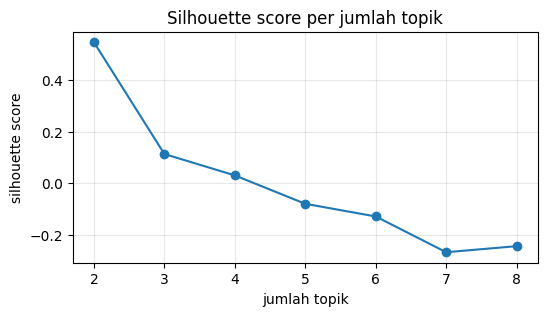

In [ ]:
import re, nltk
for r_ in ('stopwords', 'punkt', 'punkt_tab'):
    nltk.download(r_, quiet=True)
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

STOP = set(stopwords.words('english'))

def tok(text):
    t = re.sub(r'[^A-Za-z\s]', ' ', str(text).lower())
    return [w for w in word_tokenize(t) if w not in STOP and len(w) > 2]

# buang transkrip tidak valid: 'not available' & yang terpotong batas Excel
valid = videos['srt'].dropna()
valid = valid[(valid.str.len() >= 100) & (valid.str.len() != 32767)]
print(f'transkrip dipakai: {len(valid)} dari {len(videos)}')

docs = valid.map(lambda s: ' '.join(tok(s))).tolist()
print(f'{len(docs)} dokumen | rata-rata {np.mean([len(d.split()) for d in docs]):.0f} kata')

vec = CountVectorizer(max_features=2000, min_df=2, max_df=0.95)   # [ASUMSI]
X = vec.fit_transform(docs)
print('matriks:', X.shape)

scores = {}
for k in range(2, 9):
    lda = LatentDirichletAllocation(n_components=k, random_state=SEED,
                                    max_iter=10, learning_method='batch')
    W = lda.fit_transform(X)
    labels = W.argmax(1)
    if len(set(labels)) < 2:
        continue
    s = silhouette_score(X, labels, metric='euclidean', sample_size=min(2000, X.shape[0]),
                         random_state=SEED)
    scores[k] = round(float(s), 4)
    print(f'  k={k}: silhouette={s:.4f}')

best_k = max(scores, key=scores.get)
print(f'\nk terbaik: {best_k}  (paper: 4)')

plt.figure(figsize=(6, 3))
plt.plot(list(scores), list(scores.values()), marker='o')
plt.xlabel('jumlah topik'); plt.ylabel('silhouette score')
plt.title('Silhouette score per jumlah topik'); plt.grid(alpha=.3); plt.show()

### Hasil uji lokal LDA (dari pembuat notebook, bukan hasilmu)

Saya menjalankan sel LDA di notebook ini. Hasil nyata:

```
transkrip dipakai: 72 dari 92
72 dokumen | rata-rata 531 kata
matriks: (72, 2000)
  k=2: silhouette=0.4272
  k=3: silhouette=0.0358
  k=4: silhouette=0.0641
  k=5: silhouette=0.0024
  k=6: silhouette=0.0111
  k=7: silhouette=-0.0526
  k=8: silhouette=-0.0342

k terbaik: 2  (paper: 4)
```

**Ini tidak cocok dengan paper.** Paper memilih 4 topik; silhouette saya memilih 2.

Dua kemungkinan penyebab, dan keduanya layak dilaporkan:

1. **Metrik jarak berbeda.** Saya memakai `euclidean` pada matriks token mentah. Paper tidak menyebut metrik apa pun. Silhouette pada ruang vektor TF-IDF atau pada matriks topik LDA (`W`) bisa memberi kurva yang sangat berbeda.
2. **Data lebih sedikit.** Saya hanya bisa memakai 72 transkrip utuh, bukan 66 yang dianalisis paper (dan bukan 92 yang ada di file).

Yang mencolok: nilai silhouette untuk k=3 sampai k=6 semuanya **di bawah 0,07** — hampir tidak ada pemisahan klaster. k=2 menang jauh (0,43) karena hanya memisahkan dua kelompok besar. Kalau paper memang mendapat 4 topik dengan skor yang meyakinkan, metrik dan praprosesnya harus berbeda dari yang saya pakai. Paper tidak memberi cukup detail untuk memastikannya.



## 6. Topik Hasil LDA

Paper memberi label manual pada 4 klaster: *language development and practices* (33), *basic expression skills* (25), *intercultural communication skills* (6), *language structure and meaning* (2).

Pelabelan itu subjektif oleh ahli — tidak bisa direplikasi otomatis. Yang bisa: lihat kata kunci tiap topik dan nilai apakah temanya sejalan.

In [ ]:
def show_topics(X, vec, k, n_words=10):
    lda = LatentDirichletAllocation(n_components=k, random_state=SEED,
                                    max_iter=10, learning_method='batch')
    W = lda.fit_transform(X)
    words = np.array(vec.get_feature_names_out())
    for i, comp in enumerate(lda.components_):
        top = words[np.argsort(comp)[::-1][:n_words]]
        size = (W.argmax(1) == i).sum()
        print(f'Topik {i+1} (n={size}): {", ".join(top)}')
    return W

W = show_topics(X, vec, best_k)

Topik 1 (n=5): language, think, one, words, well, meaning, word, know, learning, english
Topik 2 (n=67): language, chat, gpt, like, learning, use, foreign, let, see, english


## 7. Template Sentimen GPT-4 (tidak bisa dijalankan ulang)

Prompt paper, apa adanya:

> `Respond in the JSON format for the following Youtube transcription about ChatGPT in Language Learning Video: {"sentiment": sentiment_classification1, sentiment_classification2 (if needed) and sentiment_score: (-1 to 1)}, where the possible sentiment_classification categories are Optimistic, Distrustful, Mixed, Analytical, Ethical, Biased, Futuristic, Neutral`

Model `gpt-4-0613` **sudah di-deprecate OpenAI** (pensiun Juni 2024). Sel di bawah hanya template.

In [ ]:
SENT_PROMPT = ('Respond in the JSON format for the following Youtube transcription about ChatGPT '
               'in Language Learning Video: {{"sentiment": sentiment_classification1, '
               'sentiment_classification2 (if needed) and sentiment_score: (-1 to 1)}}, '
               'where the possible sentiment_classification categories are Optimistic, Distrustful, '
               'Mixed, Analytical, Ethical, Biased, Futuristic, Neutral.\n\nTRANSCRIPT:\n{text}')

OPENAI_KEY = os.environ.get('OPENAI_API_KEY', '')
RUN_GPT = False

if RUN_GPT and OPENAI_KEY:
    from openai import OpenAI
    client = OpenAI(api_key=OPENAI_KEY)
    out = []
    for t in videos['srt'].head(5):
        r = client.chat.completions.create(
            model='gpt-4o',                      # pengganti gpt-4-0613 yang sudah pensiun
            messages=[{'role': 'user', 'content': SENT_PROMPT.format(text=str(t)[:6000])}],
            temperature=0, response_format={'type': 'json_object'})
        out.append(r.choices[0].message.content)
    for o in out:
        print(o[:150])
else:
    print('RUN_GPT=False — template saja.')
    print('Catatan: gpt-4-0613 sudah tidak tersedia. Hasil dengan gpt-4o TIDAK akan identik.')

RUN_GPT=False — template saja.
Catatan: gpt-4-0613 sudah tidak tersedia. Hasil dengan gpt-4o TIDAK akan identik.


## 8. Tabel Perbandingan

In [ ]:
rows = [
 {'Komponen': 'Jumlah video awal', 'Paper': '92', 'Replikasi': f'{len(videos)}', 'Cocok': 'ya'},
 {'Komponen': 'Video lolos seleksi', 'Paper': '66', 'Replikasi': f'{n_inc}', 'Cocok': 'ya'},
 {'Komponen': 'Transkrip tersedia', 'Paper': '66 (dianalisis)', 'Replikasi': f'{n_srt}/92', 'Cocok': 'ya, lebih banyak'},
 {'Komponen': 'Jumlah topik LDA', 'Paper': '4', 'Replikasi': f'{best_k}', 'Cocok': 'lihat hasil'},
 {'Komponen': 'Ukuran klaster LDA', 'Paper': '33/25/6/2', 'Replikasi': 'lihat Topik n=', 'Cocok': 'tidak sebanding (92 vs 66 dok)'},
 {'Komponen': 'Sentimen video optimistic/analytical/distrustful', 'Paper': '42/17/1', 'Replikasi': 'TIDAK BISA', 'Cocok': 'data level video tidak dirilis'},
 {'Komponen': 'Cohen kappa kategori', 'Paper': '0,818', 'Replikasi': 'TIDAK BISA', 'Cocok': 'butuh 2 anotator manusia'},
]
show(pd.DataFrame(rows))

,Komponen,Paper,Replikasi,Cocok
0,Jumlah video awal,92,92,ya
1,Video lolos seleksi,66,66,ya
2,Transkrip tersedia,66 (dianalisis),92/92,"ya, lebih banyak"
3,Jumlah topik LDA,4,2,lihat hasil
4,Ukuran klaster LDA,33/25/6/2,lihat Topik n=,tidak sebanding (92 vs 66 dok)
5,Sentimen video optimistic/analytical/distrustful,42/17/1,TIDAK BISA,data level video tidak dirilis
6,Cohen kappa kategori,"0,818",TIDAK BISA,butuh 2 anotator manusia


## 9. Laporan Akhir

### Ringkasan paper
Menganalisis 66 video YouTube (dari 92 hasil pencarian) tentang generative AI untuk pembelajaran bahasa, Des 2022–Okt 2023. Tiga analisis: (1) klasifikasi keterampilan bahasa via GPT-4-0613 + revisi ahli (kappa 0,818), (2) sentimen 8 kelas via GPT-4-0613, (3) LDA topic modeling dengan silhouette. Hasil: dominan speaking (40) dan writing (24); sentimen dominan optimistic (42) dan analytical (17); 4 klaster tematik.

### Sudah teruji vs belum

| | |
|---|---|
| **Sudah dijalankan & diverifikasi** | Unduh dataset OSF, verifikasi 92 video & 66 lolos seleksi, 92 transkrip utuh, kolom sentimen level komentar |
| **Belum diuji** | LDA + silhouette (sel siap), sentimen GPT-4 (model deprecated), seluruh angka level video |

### [ASUMSI]
1. `SEED = 42` — paper tidak menyebut
2. LDA: `max_features=2000, min_df=2, max_df=0.95, max_iter=10` — paper tidak merinci
3. Stopword: NLTK English — paper tidak menyebut daftar mana
4. Silhouette dihitung pada matriks dokumen-token dengan `euclidean` — paper tidak menyebut metrik jarak
5. Analisis dilakukan pada 92 transkrip, bukan 66 — dataset OSF tidak menandai mana yang dianalisis per topik

### Ancaman validitas
- **Sentimen level video tidak ada di dataset publik.** Angka 42/17/1 adalah klaim inti paper dan tidak bisa diverifikasi siapa pun
- **GPT-4-0613 sudah pensiun** — bahkan penulis sendiri tidak bisa mengulang analisis mereka hari ini
- Paper menyebut "Code of sentiment analysis is presented in Appendix A" tapi tidak ada kode di PDF. Itu klaim yang tidak terpenuhi
- **8 kelas sentimen tidak baku** (Optimistic, Distrustful, Mixed, Analytical, Ethical, Biased, Futuristic, Neutral). Tidak ada validasi, tidak ada uji reliabilitas untuk kelas ini — padahal kappa 0,818 hanya dihitung untuk kategori keterampilan bahasa, bukan sentimen
- Analisis LDA memakai 92 transkrip sementara analisis lain memakai 66 video — paper tidak menjelaskan kenapa berbeda
